## Phase 2 : Implémentation

### Importation des bibliothèques

In [4]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
import time


In [2]:
from skimage.util import random_noise  # Importation de la fonction random_noise

Dropdown(description='Dossier :', options=('Tile 1', 'Tile 2', 'Tile 3', 'Tile 4', 'Tile 5', 'Tile 6', 'Tile 7…

Dropdown(description='Sous-dossier :', options=('images', 'masks'), value='images')

Dropdown(description='Image :', options=(), value=None)

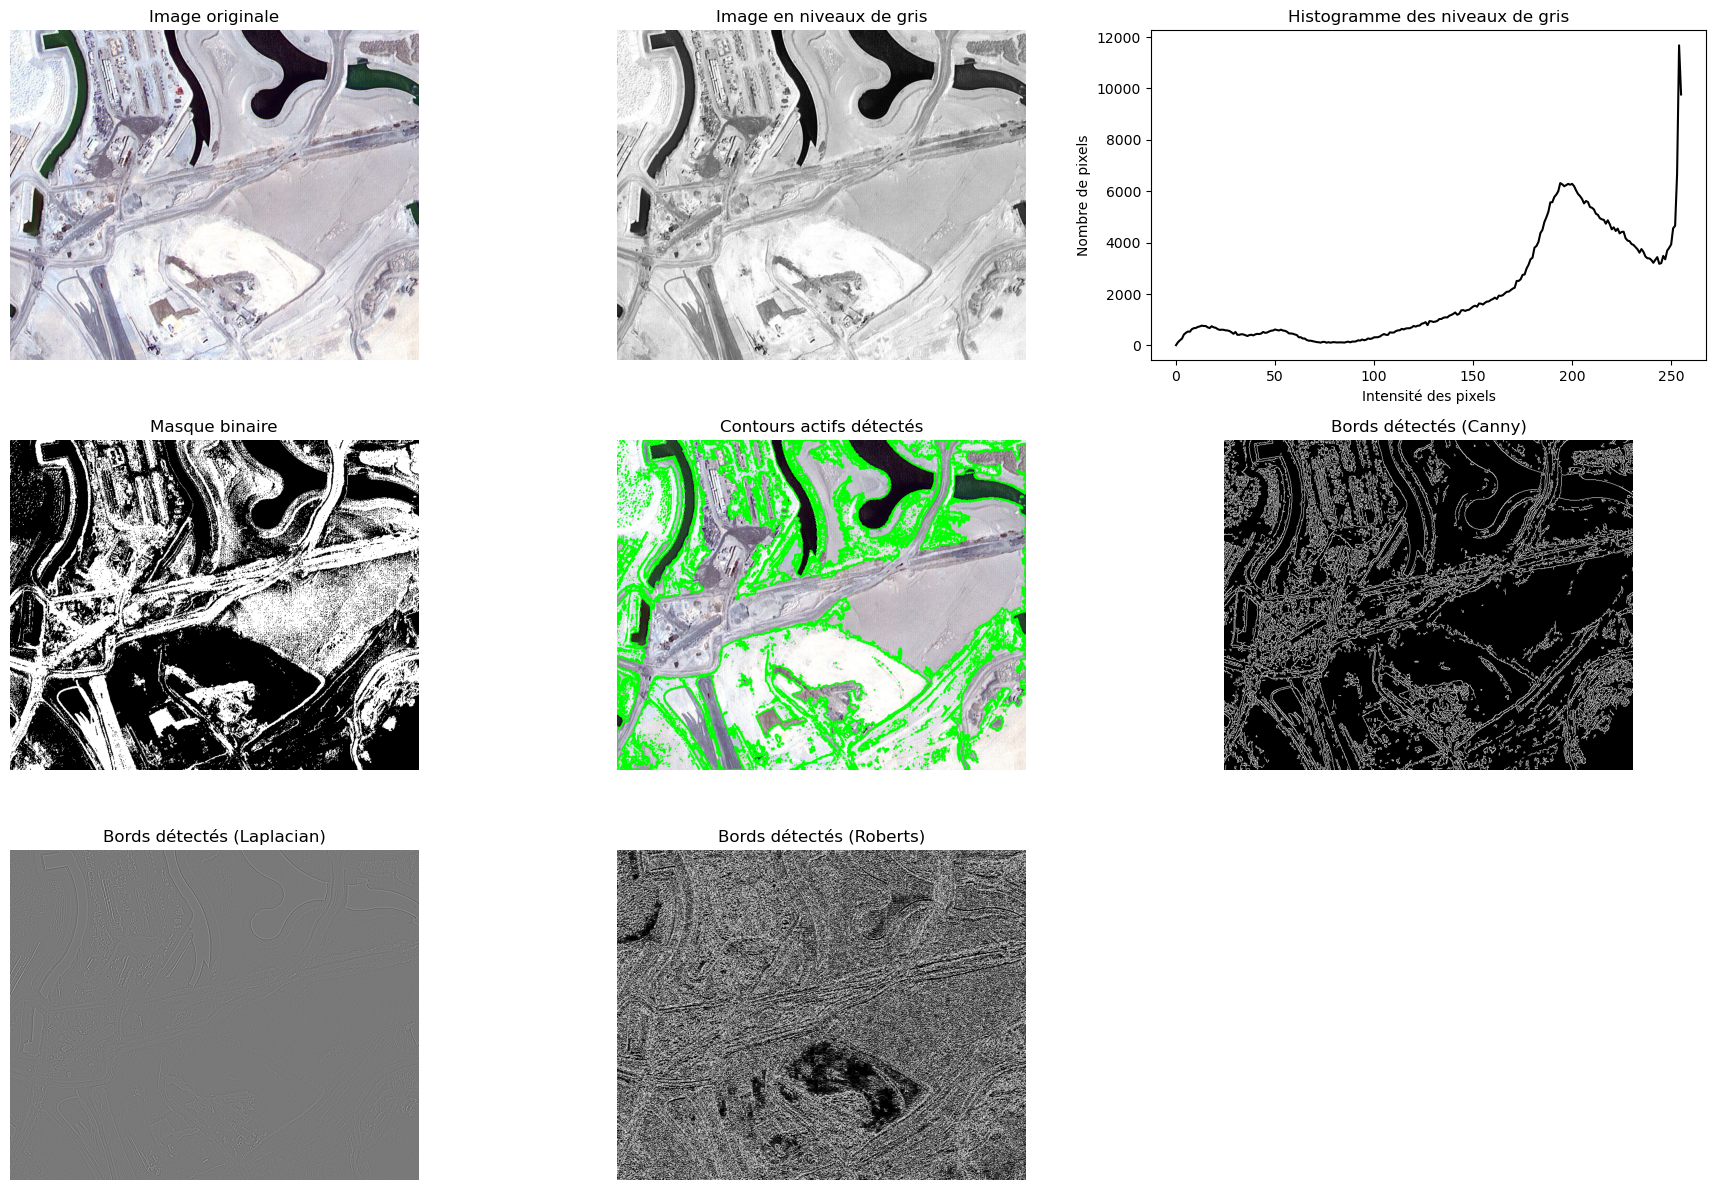

In [5]:
# Chemin de base du projet
base_path = r"C:\Users\Hp\Desktop\Computer vision\Database_mini_projet\Semantic segmentation dataset"

# Liste des dossiers présents dans le répertoire de base
folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

# Vérification de la présence de dossiers dans le répertoire de base
if not folders:
    raise ValueError("Aucun dossier trouvé dans le chemin spécifié.")

# Création des widgets pour sélectionner le dossier, le sous-dossier et l'image
folder_selector = widgets.Dropdown(options=folders, description="Dossier :")
subfolder_selector = widgets.Dropdown(options=["images", "masks"], description="Sous-dossier :")
image_selector = widgets.Dropdown(description="Image :")

# Fonction pour mettre à jour la liste des images en fonction du dossier et sous-dossier sélectionnés
def update_images_list(folder, subfolder):
    # Construction du chemin du dossier et du sous-dossier
    folder_path = os.path.join(base_path, folder)
    subfolder_path = os.path.join(folder_path, subfolder)

    # Vérification de l'existence du sous-dossier
    if not os.path.exists(subfolder_path):
        print(f"Le sous-dossier '{subfolder}' n'existe pas dans {folder}.")
        image_selector.options = ["Aucune image trouvée"]
        return

    # Récupération des fichiers image valides dans le sous-dossier
    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    
    # Si aucune image n'est trouvée, afficher un message
    if not image_files:
        image_files = ["Aucune image trouvée"]

    # Mise à jour des options du sélecteur d'images
    image_selector.options = image_files
    image_selector.value = image_files[0]  # Sélection de l'image par défaut

# Fonction pour afficher l'image sélectionnée et appliquer les traitements (seuils, contours, etc.)
def display_image(image_name):
    # Vérification de la sélection d'une image valide
    if not image_name or image_name == "Aucune image trouvée":
        print("Aucune image valide sélectionnée.")
        return
    
    # Construction du chemin complet de l'image sélectionnée
    folder = folder_selector.value
    subfolder = subfolder_selector.value
    image_path = os.path.join(base_path, folder, subfolder, image_name)
    
    # Vérification de l'existence du fichier image
    if not os.path.exists(image_path):
        print(f"Erreur : Le fichier {image_name} n'existe pas.")
        return
    
    # Chargement de l'image
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : Impossible de charger l'image.")
        return

    # Conversion de l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Extraction de l'histogramme de l'image en niveaux de gris
    histogram = cv2.calcHist([gray_image], [0], None, [256], [0, 256])

    # Création d'un masque binaire avec des seuils définis
    lower_bound, upper_bound = 100, 200
    mask = cv2.inRange(gray_image, lower_bound, upper_bound)

    # Détection des contours dans l'image
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour_image = cv2.drawContours(image.copy(), contours, -1, (0, 255, 0), 2)

    # Détection des bords à l'aide de l'algorithme Canny
    edges_canny = cv2.Canny(gray_image, 100, 200)
    laplacian = cv2.Laplacian(gray_image, cv2.CV_64F)
    
    # Détection des bords avec le filtre de Roberts
    kernel_x = np.array([[1, 0], [0, -1]], dtype=np.float32)
    kernel_y = np.array([[0, 1], [-1, 0]], dtype=np.float32)
    roberts_x = cv2.filter2D(gray_image, -1, kernel_x)
    roberts_y = cv2.filter2D(gray_image, -1, kernel_y)
    roberts = np.sqrt(roberts_x**2 + roberts_y**2)

    # Affichage des résultats
    plt.figure(figsize=(18, 12))

    # Image originale
    plt.subplot(3, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    # Image en niveaux de gris
    plt.subplot(3, 3, 2)
    plt.imshow(gray_image, cmap="gray")
    plt.title("Image en niveaux de gris")
    plt.axis("off")

    # Histogramme des niveaux de gris
    plt.subplot(3, 3, 3)
    plt.plot(histogram, color="black")
    plt.title("Histogramme des niveaux de gris")
    plt.xlabel("Intensité des pixels")
    plt.ylabel("Nombre de pixels")

    # Masque binaire
    plt.subplot(3, 3, 4)
    plt.imshow(mask, cmap="gray")
    plt.title("Masque binaire")
    plt.axis("off")

    # Contours détectés
    plt.subplot(3, 3, 5)
    plt.imshow(cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB))
    plt.title("Contours actifs détectés")
    plt.axis("off")

    # Bords détectés par Canny
    plt.subplot(3, 3, 6)
    plt.imshow(edges_canny, cmap="gray")
    plt.title("Bords détectés (Canny)")
    plt.axis("off")

    # Bords détectés par Laplacian
    plt.subplot(3, 3, 7)
    plt.imshow(laplacian, cmap="gray")
    plt.title("Bords détectés (Laplacian)")
    plt.axis("off")

    # Bords détectés par Roberts
    plt.subplot(3, 3, 8)
    plt.imshow(roberts, cmap="gray")
    plt.title("Bords détectés (Roberts)")
    plt.axis("off")
    
    # Ajustement des espaces et affichage des résultats
    plt.tight_layout()
    plt.show()

# Mise à jour de la liste des images lorsque le dossier ou sous-dossier change
def update_on_folder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]  # Réinitialisation de l'image sélectionnée

# Mise à jour de la liste des images lorsque le sous-dossier change
def update_on_subfolder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]

# Observation des changements dans les sélecteurs de dossier et sous-dossier
folder_selector.observe(update_on_folder_change, names="value")
subfolder_selector.observe(update_on_subfolder_change, names="value")

# Observation du changement dans la sélection d'image
image_selector.observe(lambda change: display_image(image_selector.value), names="value")

# Affichage des widgets
display(folder_selector, subfolder_selector, image_selector)

# Initialisation : charger les images du premier dossier et sous-dossier par défaut
update_images_list(folders[0], subfolder_selector.value)


## Phase 3: Proposition et Évaluation d'Améliorations 

### Utilisation d’autres algorithmes de segmentation ( Seuillage (Otsu), k-means, Watershed). 

Dropdown(description='Dossier :', options=('Tile 1', 'Tile 2', 'Tile 3', 'Tile 4', 'Tile 5', 'Tile 6', 'Tile 7…

Dropdown(description='Sous-dossier :', options=('images', 'masks'), value='images')

Dropdown(description='Image :', options=(), value=None)

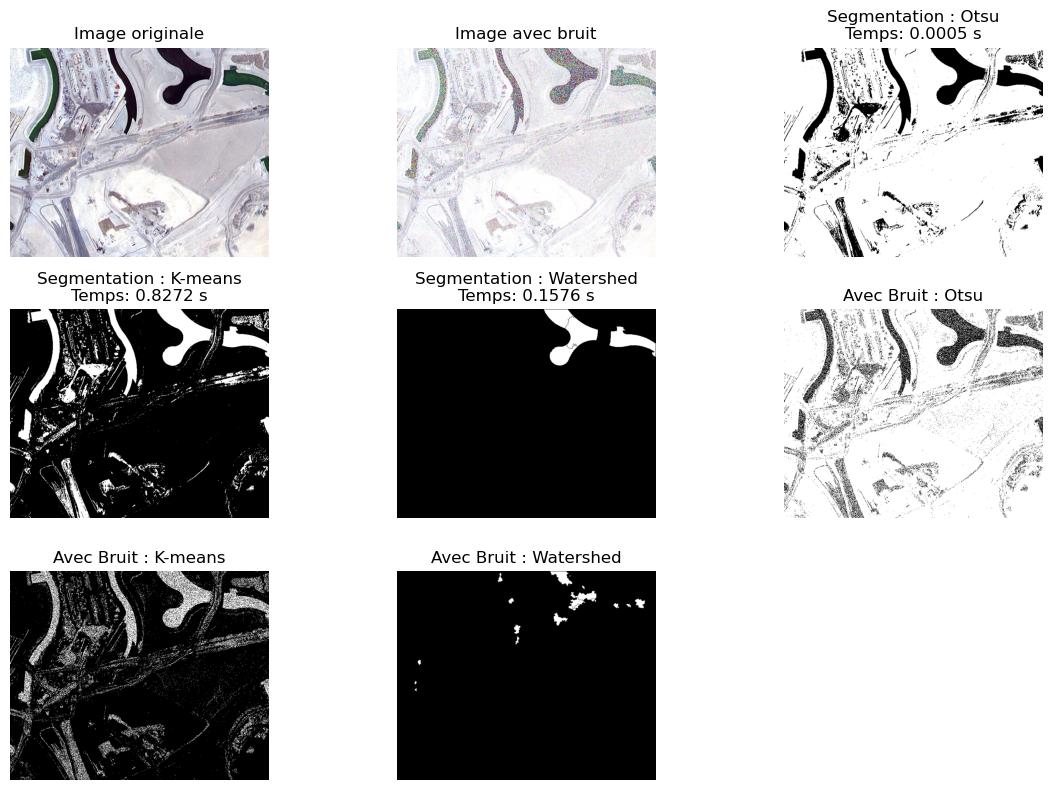

In [6]:
def apply_segmentation_methods(image):
    # Conversion de l'image en niveaux de gris pour simplifier les opérations de segmentation
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    results = {}  # Dictionnaire pour stocker les résultats de segmentation
    times = {}  # Dictionnaire pour stocker le temps d'exécution de chaque méthode

    # 1. Application du seuillage d'Otsu
    start_time = time.time()  # Enregistrement du temps de début
    _, otsu_thresh = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    times['Otsu'] = time.time() - start_time  # Calcul du temps d'exécution
    results['Otsu'] = otsu_thresh  # Stockage du résultat de la segmentation d'Otsu

    # 2. Application de K-means
    start_time = time.time()  # Enregistrement du temps de début
    Z = gray_image.reshape((-1, 1)).astype(np.float32)  # Transformation de l'image en un tableau de données 1D
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)  # Critères de terminaison pour l'algorithme K-means
    K = 2  # Nombre de clusters
    _, labels, _ = cv2.kmeans(Z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)  # Application de K-means
    kmeans_result = labels.reshape(gray_image.shape)  # Reshape des résultats en dimensions de l'image
    times['K-means'] = time.time() - start_time  # Calcul du temps d'exécution
    results['K-means'] = (kmeans_result * 255 / (K-1)).astype(np.uint8)  # Transformation des résultats en image binaire

    # 3. Application de Watershed
    start_time = time.time()  # Enregistrement du temps de début
    ret, thresh = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)  # Seuillage inversé
    sure_bg = cv2.dilate(thresh, np.ones((3,3), np.uint8), iterations=3)  # Dilatation pour obtenir le fond sûr
    dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)  # Transformation de distance pour obtenir les régions sûres
    _, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)  # Seuil pour les régions sûres avant
    unknown = cv2.subtract(sure_bg, sure_fg.astype(np.uint8))  # Calcul des pixels inconnus
    markers = cv2.connectedComponents(sure_fg.astype(np.uint8))[1] + 1  # Application de la méthode des composants connectés
    markers[unknown == 255] = 0  # Attribution des marqueurs pour les pixels inconnus
    watershed_result = cv2.cvtColor(gray_image, cv2.COLOR_GRAY2BGR)  # Conversion en image RGB pour l'application de Watershed
    cv2.watershed(watershed_result, markers)  # Application de l'algorithme Watershed
    times['Watershed'] = time.time() - start_time  # Calcul du temps d'exécution
    results['Watershed'] = (markers > 1).astype(np.uint8) * 255  # Conversion des résultats en image binaire

    return results, times  # Retourne les résultats de segmentation et les temps d'exécution

def evaluate_robustness(image, noise_level=20):
    # Fonction pour ajouter du bruit gaussien à l'image
    noisy_image = image.copy()  # Copie de l'image originale
    noise = np.random.normal(0, noise_level, image.shape).astype(np.uint8)  # Génération de bruit gaussien
    noisy_image = cv2.add(noisy_image, noise)  # Addition du bruit à l'image originale
    return noisy_image  # Retour de l'image avec bruit

def display_segmentation(image_name):
    # Fonction pour afficher les résultats de segmentation

    # Vérification si une image valide a été sélectionnée
    if not image_name or image_name == "Aucune image trouvée":
        print("Aucune image valide sélectionnée.")
        return
    
    # Construction du chemin d'accès à l'image
    folder = folder_selector.value
    subfolder = subfolder_selector.value
    image_path = os.path.join(base_path, folder, subfolder, image_name)
    
    # Vérification de l'existence du fichier image
    if not os.path.exists(image_path):
        print(f"Erreur : Le fichier {image_name} n'existe pas.")
        return
    
    # Chargement de l'image
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : Impossible de charger l'image.")
        return
    
    # Application des méthodes de segmentation
    segmentation_results, processing_times = apply_segmentation_methods(image)
    
    # Application du bruit gaussien à l'image
    noisy_image = evaluate_robustness(image)
    
    # Application des méthodes de segmentation à l'image bruitée
    noisy_segmentation_results, _ = apply_segmentation_methods(noisy_image)
    
    # Affichage des résultats
    plt.figure(figsize=(12, 8))
    
    # Affichage de l'image originale
    plt.subplot(3, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")
    
    # Affichage de l'image bruitée
    plt.subplot(3, 3, 2)
    plt.imshow(cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB))
    plt.title("Image avec bruit")
    plt.axis("off")
    
    # Affichage des résultats de segmentation pour l'image originale
    for i, (method, result) in enumerate(segmentation_results.items(), 3):
        plt.subplot(3, 3, i)
        plt.imshow(result, cmap='gray')
        plt.title(f"Segmentation : {method}\nTemps: {processing_times[method]:.4f} s")
        plt.axis("off")

    # Affichage des résultats de segmentation pour l'image bruitée
    for i, (method, result) in enumerate(noisy_segmentation_results.items(), 6):
        plt.subplot(3, 3, i)
        plt.imshow(result, cmap='gray')
        plt.title(f"Avec Bruit : {method}")
        plt.axis("off")
    
    plt.tight_layout()  # Ajuste l'affichage pour éviter les chevauchements
    plt.show()  # Affiche le graphique

# Définition du chemin de base pour les images et dossiers
base_path = r"C:\Users\Hp\Desktop\Computer vision\Database_mini_projet\Semantic segmentation dataset"
folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

# Création de widgets pour la sélection des dossiers, sous-dossiers et images
folder_selector = widgets.Dropdown(options=folders, description="Dossier :")
subfolder_selector = widgets.Dropdown(options=["images", "masks"], description="Sous-dossier :")
image_selector = widgets.Dropdown(description="Image :")

# Mise à jour des options d'images selon le dossier et sous-dossier sélectionnés
def update_images_list(folder, subfolder):
    folder_path = os.path.join(base_path, folder)
    subfolder_path = os.path.join(folder_path, subfolder)
    if not os.path.exists(subfolder_path):
        image_selector.options = ["Aucune image trouvée"]
        return
    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    if not image_files:
        image_files = ["Aucune image trouvée"]
    image_selector.options = image_files
    image_selector.value = image_files[0]

# Gestion des changements de sélection pour les dossiers et sous-dossiers
def update_on_folder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]

def update_on_subfolder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]

# Observation des changements dans les sélections
folder_selector.observe(update_on_folder_change, names="value")
subfolder_selector.observe(update_on_subfolder_change, names="value")
image_selector.observe(lambda change: display_segmentation(image_selector.value), names="value")

# Affichage des widgets et mise à jour initiale de la liste d'images
display(folder_selector, subfolder_selector, image_selector)
update_images_list(folders[0], subfolder_selector.value)


### l’algorithme de contours actifs

Dropdown(description='Dossier :', options=('Tile 1', 'Tile 2', 'Tile 3', 'Tile 4', 'Tile 5', 'Tile 6', 'Tile 7…

Dropdown(description='Sous-dossier :', options=('images', 'masks'), value='images')

Dropdown(description='Image :', options=(), value=None)

Temps de traitement : 0.13 secondes


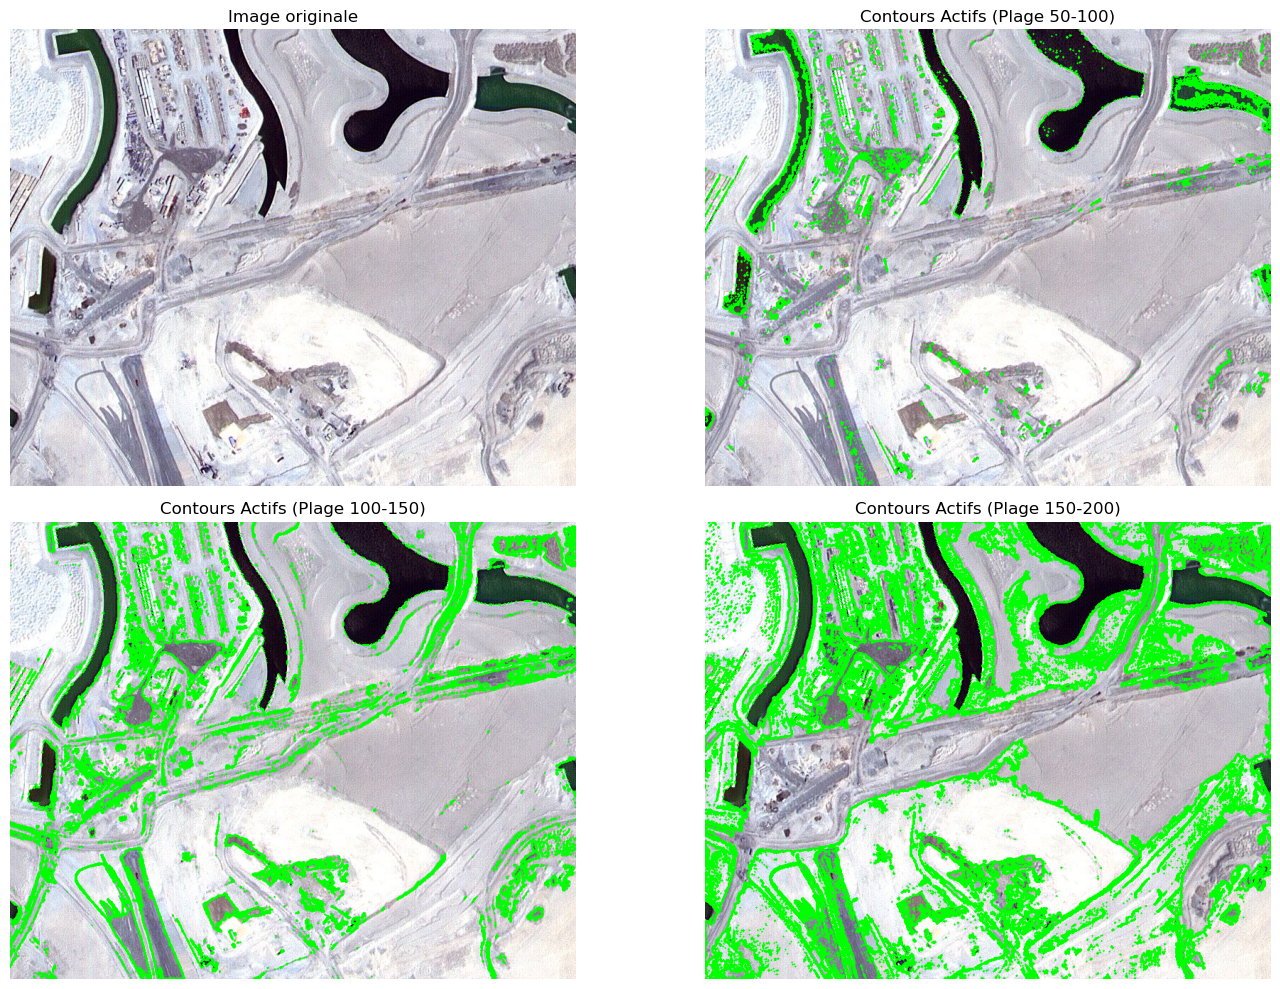


--- Évaluation des segments ---
Entropie du masque Plage 50-100 : -27041500.08
Contraste du masque Plage 50-100 : -124.00
Entropie du masque Plage 100-150 : -89201275.45
Contraste du masque Plage 100-150 : -64.19
Entropie du masque Plage 150-200 : -355916289.59
Contraste du masque Plage 150-200 : -11.15


In [7]:
# Chemin de base où se trouvent les dossiers d'images
base_path = r"C:\Users\Hp\Desktop\Computer vision\Database_mini_projet\Semantic segmentation dataset"

# Liste des dossiers disponibles dans le chemin de base
folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

# Vérification s'il y a des dossiers disponibles
if not folders:
    raise ValueError("Aucun dossier trouvé dans le chemin spécifié.")

# Création des widgets pour sélectionner un dossier, un sous-dossier et une image
folder_selector = widgets.Dropdown(options=folders, description="Dossier :")
subfolder_selector = widgets.Dropdown(options=["images", "masks"], description="Sous-dossier :")
image_selector = widgets.Dropdown(description="Image :")

# Fonction pour mettre à jour la liste des images disponibles
def update_images_list(folder, subfolder):
    """
    Met à jour la liste des images disponibles dans le sous-dossier sélectionné.
    :param folder: Dossier sélectionné
    :param subfolder: Sous-dossier sélectionné (images ou masks)
    """
    # Chemin complet du dossier sélectionné
    folder_path = os.path.join(base_path, folder)
    # Chemin complet du sous-dossier sélectionné
    subfolder_path = os.path.join(folder_path, subfolder)

    # Vérification si le sous-dossier existe
    if not os.path.exists(subfolder_path):
        print(f"Le sous-dossier '{subfolder}' n'existe pas dans {folder}.")
        image_selector.options = ["Aucune image trouvée"]
        return

    # Liste des fichiers image valides (jpg, png, jpeg)
    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    # Mise à jour des options du sélecteur d'images
    image_selector.options = image_files if image_files else ["Aucune image trouvée"]
    # Sélection de la première image par défaut
    image_selector.value = image_files[0] if image_files else "Aucune image trouvée"

# Fonction pour afficher et analyser une image sélectionnée
def display_image(image_name):
    """
    Affiche l'image sélectionnée et applique l'algorithme de contours actifs.
    :param image_name: Nom de l'image sélectionnée
    """
    # Vérification si une image valide est sélectionnée
    if not image_name or image_name == "Aucune image trouvée":
        print("Aucune image valide sélectionnée.")
        return

    # Récupération du dossier et du sous-dossier sélectionnés
    folder = folder_selector.value
    subfolder = subfolder_selector.value
    # Chemin complet de l'image sélectionnée
    image_path = os.path.join(base_path, folder, subfolder, image_name)

    # Vérification si le fichier image existe
    if not os.path.exists(image_path):
        print(f"Erreur : Le fichier {image_name} n'existe pas.")
        return

    # Chargement de l'image
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : Impossible de charger l'image.")
        return

    # Conversion de l'image en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Définition des plages d'intensité pour générer différents masques
    intensity_ranges = [
        (50, 100),   # Masque faible intensité
        (100, 150),  # Masque intensité moyenne
        (150, 200),  # Masque forte intensité
    ]

    # Liste pour stocker les résultats des masques et des contours
    contour_results = []

    # Début du calcul du temps de traitement
    start_time = time.time()

    # Application de l'algorithme de contours actifs pour chaque plage d'intensité
    for lower_bound, upper_bound in intensity_ranges:
        # Génération d'un masque binaire en fonction de la plage d'intensité
        mask = cv2.inRange(gray_image, lower_bound, upper_bound)

        # Application de l'algorithme de contours actifs
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        # Copie de l'image originale pour dessiner les contours
        contour_image = image.copy()
        cv2.drawContours(contour_image, contours, -1, (0, 255, 0), 2)

        # Sauvegarde des résultats (masque, image avec contours, titre)
        contour_results.append((mask, contour_image, f"Plage {lower_bound}-{upper_bound}"))

    # Calcul du temps de traitement
    processing_time = time.time() - start_time
    print(f"Temps de traitement : {processing_time:.2f} secondes")

    # --- Affichage des résultats ---
    plt.figure(figsize=(15, 10))

    # Affichage de l'image originale
    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    # Affichage des résultats des contours actifs pour chaque masque
    for i, (mask, contour_img, title) in enumerate(contour_results):
        # Affichage de l'image avec les contours actifs
        plt.subplot(2, 2, i + 2)
        plt.imshow(cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Contours Actifs ({title})")
        plt.axis("off")

    # Affichage de la figure
    plt.tight_layout()
    plt.show()

    # --- Évaluation des segments ---
    print("\n--- Évaluation des segments ---")
    for i, (mask, contour_img, title) in enumerate(contour_results):
        # Calcul de l'entropie du masque (mesure de la complexité)
        entropy = -np.sum(mask * np.log2(mask + 1e-10))  # Éviter log(0)
        print(f"Entropie du masque {title} : {entropy:.2f}")

        # Calcul du contraste entre les pixels du masque et le fond
        contrast = np.mean(gray_image[mask > 0]) - np.mean(gray_image[mask == 0])
        print(f"Contraste du masque {title} : {contrast:.2f}")

# Mise à jour de la liste des images lorsque le dossier ou le sous-dossier change
folder_selector.observe(lambda change: update_images_list(folder_selector.value, subfolder_selector.value), names="value")
subfolder_selector.observe(lambda change: update_images_list(folder_selector.value, subfolder_selector.value), names="value")

# Affichage de l'image sélectionnée
image_selector.observe(lambda change: display_image(change.new), names="value")

# Affichage des widgets (sélecteurs de dossier, sous-dossier et image)
display(folder_selector, subfolder_selector, image_selector)

# Chargement des images du premier dossier par défaut
if folders:
    update_images_list(folders[0], subfolder_selector.value)

### Comparaison avec d'autres techniques de détection de contours 

#### Sobel et Canny 

Dropdown(description='Dossier :', options=('Tile 1', 'Tile 2', 'Tile 3', 'Tile 4', 'Tile 5', 'Tile 6', 'Tile 7…

Dropdown(description='Sous-dossier :', options=('images', 'masks'), value='images')

Dropdown(description='Image :', options=(), value=None)

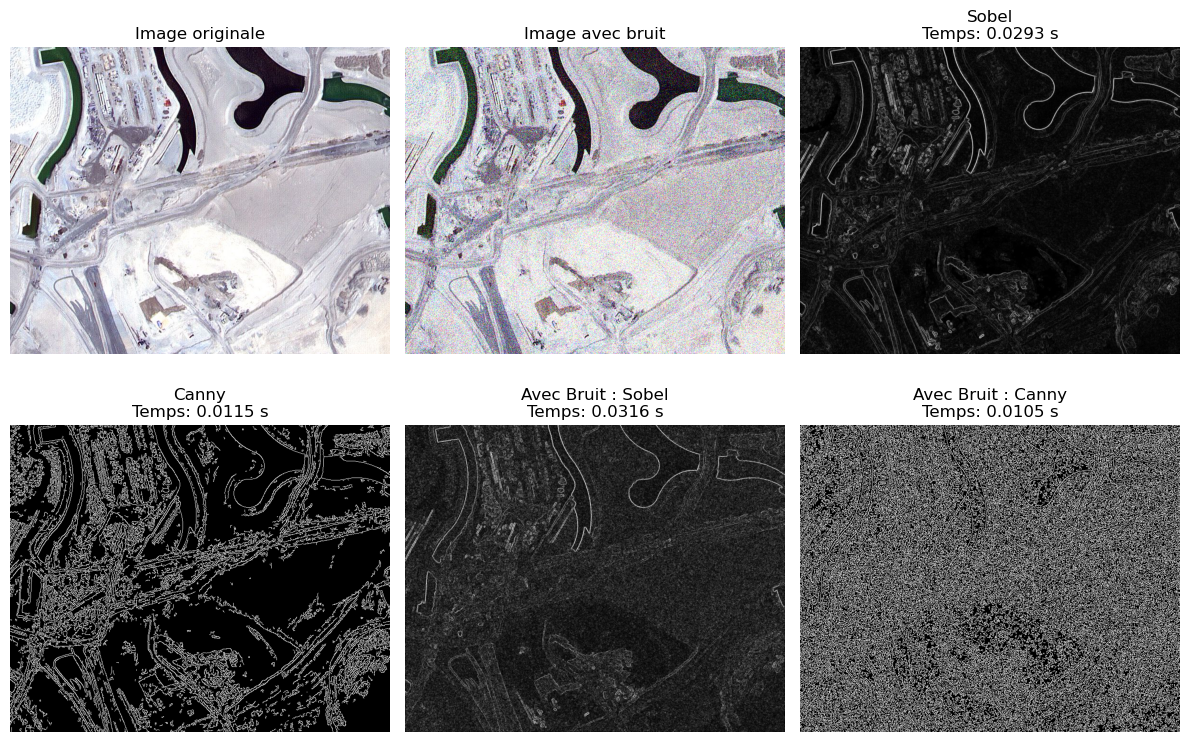

In [8]:
def apply_edge_detection(image):
    # Conversion de l'image en niveaux de gris pour simplifier les opérations de détection de contours
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32)
    results = {}  # Dictionnaire pour stocker les résultats
    times = {}  # Dictionnaire pour stocker les temps d'exécution des méthodes

    # 1. Filtrage de Sobel (détection de contours)
    start_time = time.time()  # Enregistrement du temps de début
    sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)  # Filtre Sobel en direction X
    sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)  # Filtre Sobel en direction Y
    sobel = np.sqrt(sobel_x**2 + sobel_y**2)  # Calcul du module du gradient
    times['Sobel'] = time.time() - start_time  # Calcul du temps d'exécution
    results['Sobel'] = (sobel / sobel.max() * 255).astype(np.uint8)  # Normalisation du résultat

    # 2. Détection des contours de Canny
    start_time = time.time()  # Enregistrement du temps de début
    canny_edges = cv2.Canny(gray_image.astype(np.uint8), 100, 200)  # Application de l'algorithme de Canny
    times['Canny'] = time.time() - start_time  # Calcul du temps d'exécution
    results['Canny'] = canny_edges  # Stockage des résultats de Canny
    
    return results, times  # Retourne les résultats de la détection de contours et les temps d'exécution

def add_gaussian_noise(image, sigma=0.2):
    # Fonction pour ajouter du bruit gaussien à l'image
    noisy_image = random_noise(image, mode='gaussian', var=sigma**2)  # Ajout du bruit gaussien avec une variance définie
    return (noisy_image * 255).astype(np.uint8)  # Normalisation et conversion en entier 8 bits

# Chemin de base pour les images
base_path = r"C:\Users\Hp\Desktop\Computer vision\Database_mini_projet\Semantic segmentation dataset"

# Liste des dossiers disponibles dans le chemin de base
folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

# Vérification de l'existence des dossiers
if not folders:
    raise ValueError("Aucun dossier trouvé dans le chemin spécifié.")

# Widgets pour sélectionner un dossier, un sous-dossier et une image
folder_selector = widgets.Dropdown(options=folders, description="Dossier :")
subfolder_selector = widgets.Dropdown(options=["images", "masks"], description="Sous-dossier :")
image_selector = widgets.Dropdown(description="Image :")

# Fonction pour mettre à jour la liste des images disponibles selon le dossier et sous-dossier choisis
def update_images_list(folder, subfolder):
    folder_path = os.path.join(base_path, folder)
    subfolder_path = os.path.join(folder_path, subfolder)

    if not os.path.exists(subfolder_path):  # Vérification de l'existence du sous-dossier
        print(f"Le sous-dossier '{subfolder}' n'existe pas dans {folder}.")
        image_selector.options = ["Aucune image trouvée"]
        return

    # Liste des fichiers image valides
    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    
    if not image_files:
        image_files = ["Aucune image trouvée"]  # Si aucune image, afficher ce message

    image_selector.options = image_files
    image_selector.value = image_files[0]  # Sélectionner automatiquement la première image

# Fonction pour afficher l'image, appliquer les filtres et afficher les résultats
def display_image(image_name):
    # Vérification si une image valide a été sélectionnée
    if not image_name or image_name == "Aucune image trouvée":
        print("Aucune image valide sélectionnée.")
        return
    
    folder = folder_selector.value
    subfolder = subfolder_selector.value
    image_path = os.path.join(base_path, folder, subfolder, image_name)
    
    # Vérification de l'existence du fichier image
    if not os.path.exists(image_path):
        print(f"Erreur : Le fichier {image_name} n'existe pas.")
        return
    
    # Chargement de l'image
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : Impossible de charger l'image.")
        return

    # Application des filtres Sobel et Canny sur l'image originale
    segmentation_results, processing_times = apply_edge_detection(image)

    # l'ajout du bruit gaussien et réappliquer les filtres
    noisy_image = add_gaussian_noise(image)
    noisy_segmentation_results, noisy_processing_times = apply_edge_detection(noisy_image)

    # Affichage des résultats
    plt.figure(figsize=(12, 8))
    
    # Affichage de l'image originale
    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    # Affichage de l'image avec bruit
    plt.subplot(2, 3, 2)
    plt.imshow(cv2.cvtColor(noisy_image, cv2.COLOR_BGR2RGB))
    plt.title("Image avec bruit")
    plt.axis("off")

    # Affichage des résultats des filtres pour l'image originale
    for i, (method, result) in enumerate(segmentation_results.items(), 3):
        plt.subplot(2, 3, i)
        plt.imshow(result, cmap='gray')
        plt.title(f"{method}\nTemps: {processing_times[method]:.4f} s")
        plt.axis("off")

    # Affichage des résultats des filtres pour l'image bruitée
    for i, (method, result) in enumerate(noisy_segmentation_results.items(), 5):
        plt.subplot(2, 3, i)
        plt.imshow(result, cmap='gray')
        plt.title(f"Avec Bruit : {method}\nTemps: {noisy_processing_times[method]:.4f} s")
        plt.axis("off")

    plt.tight_layout()  # Ajuste l'affichage pour éviter les chevauchements
    plt.show()

# Mettre à jour la liste des images lorsque le dossier ou sous-dossier est changé
def update_on_folder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]  # Réinitialiser l'image sélectionnée

def update_on_subfolder_change(change):
    update_images_list(folder_selector.value, subfolder_selector.value)
    image_selector.value = image_selector.options[0]  # Réinitialiser l'image sélectionnée

# Observation des changements dans les sélections
folder_selector.observe(update_on_folder_change, names="value")
subfolder_selector.observe(update_on_subfolder_change, names="value")

# Déclenchement de l'affichage de l'image lorsque l'image est sélectionnée
image_selector.observe(lambda change: display_image(image_selector.value), names="value")

# Affichage des widgets pour la sélection
display(folder_selector, subfolder_selector, image_selector)

# Initialisation : charger les images du premier dossier et sous-dossier par défaut
update_images_list(folders[0], subfolder_selector.value)


### Comparaison avec d'autres techniques de segmentation. 

#### Division-Fusion

Dropdown(description='Dossier :', options=('Tile 1', 'Tile 2', 'Tile 3', 'Tile 4', 'Tile 5', 'Tile 6', 'Tile 7…

Dropdown(description='Sous-dossier :', options=('images', 'masks'), value='images')

Dropdown(description='Image :', options=(), value=None)

C:\Users\Hp\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Hp\anaconda3\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Hp\anaconda3\Lib\site-packages\numpy\core\_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Hp\anaconda3\Lib\site-packages\numpy\core\_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\Hp\anaconda3\Lib\site-packages\numpy\core\_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Hp\AppData\Local\Temp\ipykernel_13624\1325549484.py:45: RuntimeWarning: invalid value encountered in cast
  segmented[x:x+w, y:y+h] = np.mean(image[x:x

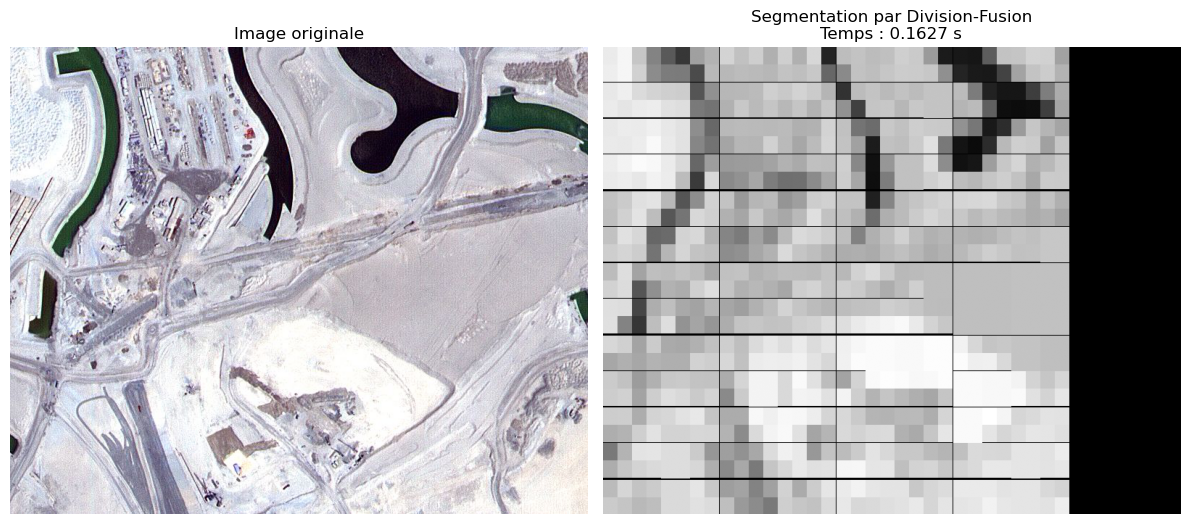

In [9]:


# Chemin de base des images
base_path = r"C:\Users\Hp\Desktop\Computer vision\Database_mini_projet\Semantic segmentation dataset"

# Liste des dossiers disponibles
folders = [f for f in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, f))]

# Widgets interactifs
folder_selector = widgets.Dropdown(options=folders, description="Dossier :")
subfolder_selector = widgets.Dropdown(options=["images", "masks"], description="Sous-dossier :")
image_selector = widgets.Dropdown(description="Image :")

# Fonction pour mettre à jour la liste des images
def update_images_list(folder, subfolder):
    folder_path = os.path.join(base_path, folder)
    subfolder_path = os.path.join(folder_path, subfolder)

    if not os.path.exists(subfolder_path):
        image_selector.options = ["Aucune image trouvée"]
        return

    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    image_selector.options = image_files if image_files else ["Aucune image trouvée"]

# --- Implémentation de Division-Fusion (Split & Merge) ---
def split_and_merge(image, min_size=20, std_threshold=15):
    """
    Implémente l'algorithme de segmentation par Division-Fusion.

    Args:
        image: Image en niveaux de gris (numpy array).
        min_size: Taille minimale d'une région avant arrêt de la division.
        std_threshold: Seuil de variance pour fusionner les régions.

    Returns:
        Image segmentée.
    """
    height, width = image.shape
    segmented = np.zeros_like(image)

    def split(x, y, w, h):
        """
        Fonction récursive pour diviser et fusionner les régions.
        """
        if w <= min_size or h <= min_size:
            segmented[x:x+w, y:y+h] = np.mean(image[x:x+w, y:y+h])
            return

        mean_val = np.mean(image[x:x+w, y:y+h])
        std_val = np.std(image[x:x+w, y:y+h])

        # Si la variance est faible, fusionner la région
        if std_val < std_threshold:
            segmented[x:x+w, y:y+h] = mean_val
            return

        # Sinon, diviser en 4 sous-régions
        hw, hh = w // 2, h // 2
        split(x, y, hw, hh)  # Haut-Gauche
        split(x + hw, y, hw, hh)  # Bas-Gauche
        split(x, y + hh, hw, hh)  # Haut-Droite
        split(x + hw, y + hh, hw, hh)  # Bas-Droite

    split(0, 0, width, height)
    return segmented

# Fonction principale pour afficher la segmentation
def display_segmentation(image_name):
    if not image_name or image_name == "Aucune image trouvée":
        print("Aucune image valide sélectionnée.")
        return

    folder = folder_selector.value
    subfolder = subfolder_selector.value
    image_path = os.path.join(base_path, folder, subfolder, image_name)

    if not os.path.exists(image_path):
        print(f"Erreur : Le fichier {image_name} n'existe pas.")
        return

    # Chargerment l'image
    image = cv2.imread(image_path)
    if image is None:
        print("Erreur : Impossible de charger l'image.")
        return

    # Conversion en niveaux de gris
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # --- Application de la segmentation Division-Fusion ---
    start_time = time.time()  # Début du chronomètre
    segmented_image = split_and_merge(gray_image)
    processing_time = time.time() - start_time  # Temps d'exécution

    # --- Affichage des résultats ---
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Image originale")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(segmented_image, cmap="gray")
    plt.title(f"Segmentation par Division-Fusion\nTemps : {processing_time:.4f} s")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Mis à jour des images lorsque le dossier ou le sous-dossier change
folder_selector.observe(lambda change: update_images_list(folder_selector.value, subfolder_selector.value), names="value")
subfolder_selector.observe(lambda change: update_images_list(folder_selector.value, subfolder_selector.value), names="value")

# Affichage l'image sélectionnée
image_selector.observe(lambda change: display_segmentation(change.new), names="value")

# Affichage des widgets
display(folder_selector, subfolder_selector, image_selector)

# Chargement les images du premier dossier par défaut
if folders:
    update_images_list(folders[0], subfolder_selector.value)
